# 4 · Coupled sectors, rationing and automatic differentiation

With `coupled = true` the departments interact through the technical matrix `A`, through three optional, independent mechanisms:

1. **Capital mobility** `μ·(rᵢ − r̄)·Cᵢ`: constant capital moves towards sectors with above-average profit rates. Profit rates are measured at Sraffa prices of production, and `r̄` is the `C`-weighted mean, so the term reallocates capital without creating or destroying it.
2. **Aggregate realization pressure** (`realization = true`): planned reinvestment is scaled down when current outputs cannot cover the intermediate demand implied by `A`.
3. **Per-sector quantity rationing** (`rationing = true`): an exact fixed point of rationing with Leontief technology, solved inside the right-hand side of the ODE.

The second half of the notebook uses ForwardDiff to get exact Jacobians of the model, including through the rationing fixed point.

In [1]:
include(joinpath("..", "..", "src", "MarxKapital.jl"))
using Plots, Random, LinearAlgebra
gr(fmt = :png, size = (760, 420), margin = 3Plots.mm)

MarxKapital loaded. Type  model_help()  to get started.


Plots.GRBackend()

## 1. Independent against coupled accumulation

The same eight departments and the same matrix `A`, with and without capital mobility. We follow each sector's share of total constant capital.

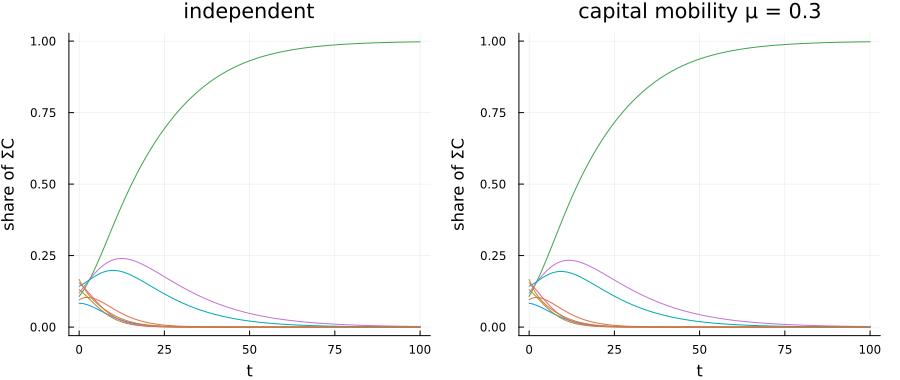

In [2]:
shares(sol, N) = reduce(hcat, [u[1:N] ./ sum(u[1:N]) for u in sol.u])'

N = 8
Random.seed!(2); sol0, depts, _ = simulate_Ndept(N, T = 100.0, seed = 2)
sol1, _, p1 = simulate_Ndept_custom(depts, T = 100.0, seed = 2, coupled = true, μ = 0.3)
plot(plot(sol0.t, shares(sol0, N), title = "independent", legend = false),
     plot(sol1.t, shares(sol1, N), title = "capital mobility μ = 0.3", legend = false),
     xlabel = "t", ylabel = "share of ΣC", layout = (1, 2), size = (900, 380), link = :y)

One sector takes over in both runs. Without coupling, each sector's variable capital grows at its own rate `σ_v·e`, and the fastest sector wins:

In [3]:
(growth_V = round.([d.σ_v * d.e for d in depts], digits = 3),
 r = round.([profit_rate(d) for d in depts], digits = 3))

(growth_V = [0.211, 0.246, 0.44, 0.376, 0.151, 0.36, 0.155, 0.216], r = [0.364, 0.414, 0.542, 0.568, 0.395, 0.458, 0.327, 0.244])

Here that sector also has a high profit rate, so mobility moves capital the same way and speeds up the concentration. Without a price mechanism, sectoral profit rates do not depend on the sectors' relative sizes, so nothing stops it: the coupled model has no interior balanced growth. Notebook 6 adds market prices that give it one.

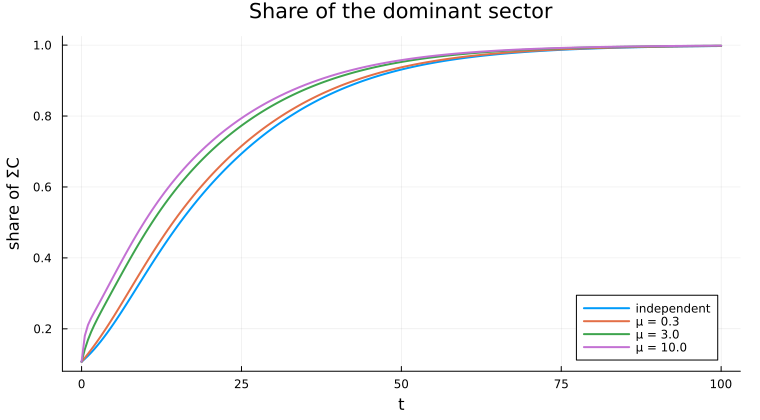

In [4]:
dominant = argmax(sol0.u[end][1:N])
plt = plot(xlabel = "t", ylabel = "share of ΣC", legend = :bottomright,
           title = "Share of the dominant sector")
for μ in (0.0, 0.3, 3.0, 10.0)
    s, _, _ = simulate_Ndept_custom(depts, T = 100.0, seed = 2, coupled = μ > 0, μ = μ)
    plot!(plt, s.t, [u[dominant] / sum(u[1:N]) for u in s.u], lw = 2,
          label = μ == 0 ? "independent" : "μ = $μ")
end
plt

Profit rates at prices of production, `compute_price_profit_rates`, are what the mobility term compares:

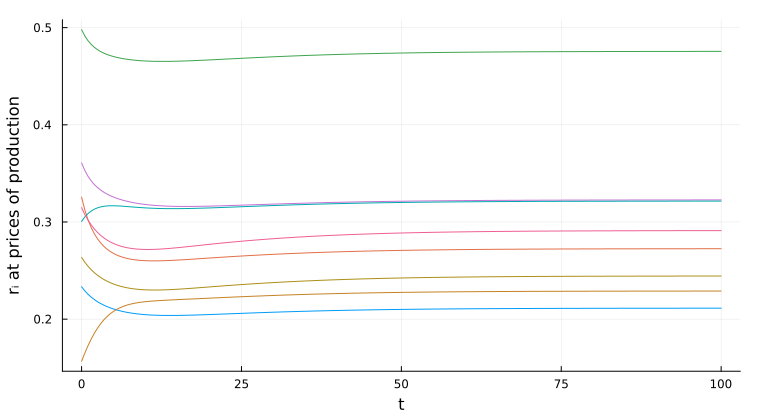

In [5]:
rp = compute_price_profit_rates(sol1, p1)
plot(sol1.t, rp', legend = false, xlabel = "t", ylabel = "rᵢ at prices of production")

## 2. Realization and rationing

The two supply-side mechanisms brake accumulation when the technical structure `A` cannot support current output levels. We run them from the same economy, with mobility `μ = 0.3`, and compare total capital with the mobility-only run.

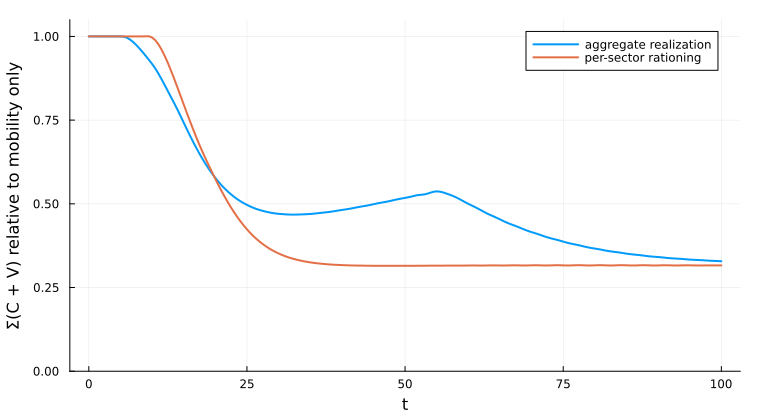

In [6]:
variants = [("mobility", (;)), ("+ realization", (realization = true,)),
             ("+ rationing", (rationing = true,))]
sols = map(variants) do (name, kw)
    sol, _, p = simulate_Ndept_custom(depts; T = 100.0, seed = 2, coupled = true,
                                          μ = 0.3, kw...)
    (name = name, sol = sol, p = p)
end
total(v) = [sum(u) for u in v.sol.u]
plot(sols[1].sol.t, [total(sols[2]) ./ total(sols[1]) total(sols[3]) ./ total(sols[1])],
     lw = 2, label = ["aggregate realization" "per-sector rationing"], xlabel = "t",
     ylabel = "Σ(C + V) relative to mobility only", ylims = (0, 1.05))

Both mechanisms start to bind after about ten time units, once output outgrows what the technical structure can supply. By `t = 100`, total capital is about a third of the mobility-only run.

## 3. Exact Jacobians of the ODE

`system_jacobian(p, X)` differentiates the right-hand side by forward-mode automatic differentiation. It works with `rationing = true` too: the rationing fixed point is differentiated through the implicit function theorem, not by unrolling the iteration. We evaluate it at `t = 10`, while capital is still spread over the sectors.

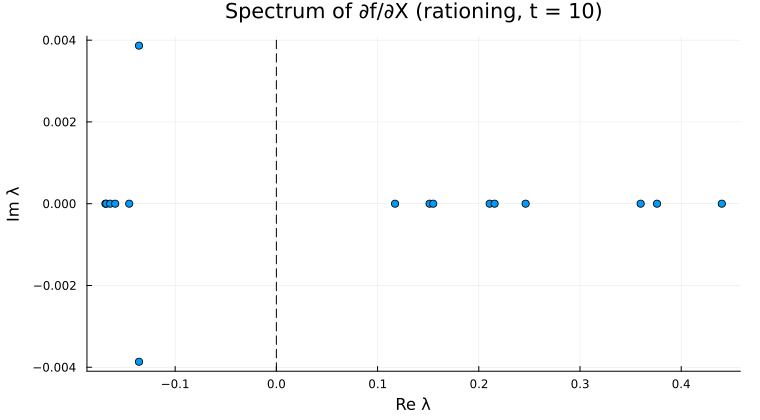

In [7]:
v = sols[3]
X = v.sol(10.0) ./ sum(v.sol(10.0))   # the field is homogeneous of degree 1: scale is irrelevant to J
J = system_jacobian(v.p, X)
λs = eigvals(J)
scatter(real.(λs), imag.(λs), xlabel = "Re λ", ylabel = "Im λ", legend = false,
        title = "Spectrum of ∂f/∂X (rationing, t = 10)")
vline!([0.0], color = :black, ls = :dash)

`parameter_jacobian` gives the sensitivity of the vector field to a parameter, here the mobility coefficient `μ`.

In [8]:
parameter_jacobian(v.p, X, :μ)

16-element Vector{Float64}:
 -0.003482619576465112
 -0.004287166744514402
  0.029332337862886495
 -0.006648882020864481
 -0.002522420195154831
 -0.006341550720397021
 -0.002222091780274828
 -0.0038276068252157906
  0.0
  0.0
  0.0
  0.0
  0.0
  0.0
  0.0
  0.0

The first eight entries are `∂(dCᵢ/dt)/∂μ`: more mobility moves constant capital into the dominant sector and out of all the others, and the entries add up to almost zero because the mobility term conserves total constant capital. The last eight, for variable capital, are zero, because `μ` only moves constant capital (`μ_v` moves variable capital).

## 4. The rationing map: spectrum and damping

Rationing is solved by a damped fixed-point iteration `ρ ← ρ − α(ρ − F(ρ))`. `rationing_jacobian` returns the exact Jacobian of `F` at the fixed point. Its spectrum lies in `[−1, 0]`, and `−1` is an eigenvalue once any sector is rationed (Proposition 1 in the paper). The damped step converges locally for every `α ∈ (0, 1)`: undamped iteration (`α = 1`) sits on a flip boundary. The library's default, `α = 2/3`, minimizes the contraction rate.

In [9]:
Random.seed!(1)
M = 12
Am = create_technical_matrix(M, density = 0.5)
σ_c = fill(0.5, M); S = 5 .+ 10rand(M); O = 0.3 .+ 0.5rand(M)
jr = rationing_jacobian(Am, σ_c, S, O)
(eigenvalues = round.(real.(jr.eigenvalues), digits = 4), α_max = jr.α_max,
 α_optimal = jr.α_optimal, spectral_radius = jr.spectral_radius)

(eigenvalues = [-1.0, -0.5573, -0.3799, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0], α_max = 1.0000000000000706, α_optimal = 0.666666666666698, spectral_radius = 0.33333333333333337)

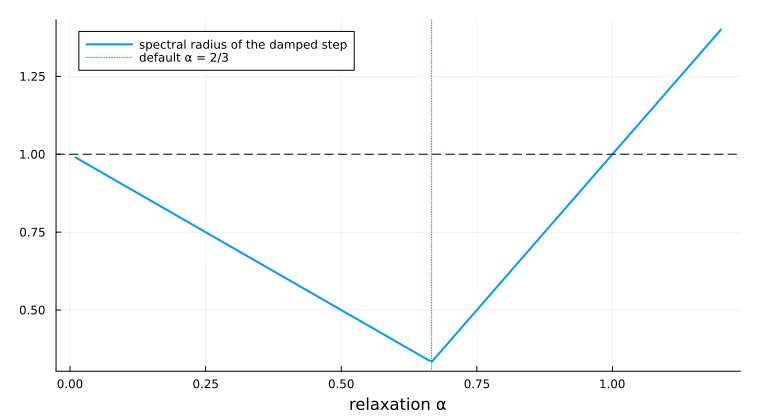

In [10]:
αs = range(0.01, 1.2, length = 200)
plot(αs, [damped_spectral_radius(jr.eigenvalues, α) for α in αs], lw = 2,
     label = "spectral radius of the damped step", xlabel = "relaxation α")
hline!([1.0], color = :black, ls = :dash, label = "")
vline!([DEFAULT_RELAXATION], ls = :dot, label = "default α = 2/3")

## 5. Bifurcation of the rationing iteration

`rationing_bifurcation` continues the fixed point in the scale of demand `s` with BifurcationKit and classifies where the damped iteration loses stability. `plot_bifurcation` draws the spectral radius along the branch and the local convergence region `α < α_max(s)`.

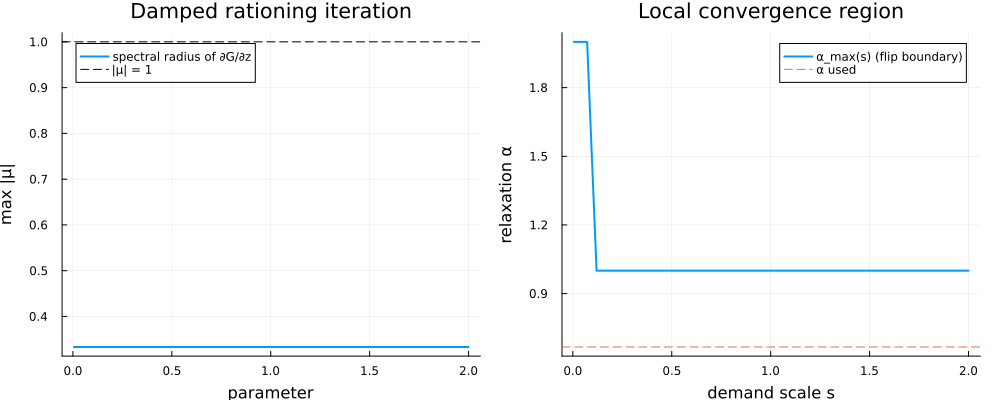

In [11]:
br = rationing_bifurcation(Am, σ_c, S, O; scale = (0.005, 2.0))
plot_bifurcation(br; title = "Damped rationing iteration")